<a href="https://colab.research.google.com/github/Sana-sudo322/ANN-Customer-Churn-PREDICTION/blob/main/CNN1st.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import os
import numpy as np
from google.colab import drive
drive.mount('/content/drive')

# Fixed typo: changed 'm=MyDrive' to 'MyDrive'
data_path = '/content/drive/MyDrive/dataset/cifar10.npz'

if os.path.exists(data_path):
  data = np.load(data_path)
  x_train = data['x_train']
  y_train = data['y_train']
  x_test = data['x_test']
  y_test = data['y_test']
else:
  (x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
  os.makedirs(os.path.dirname(data_path), exist_ok=True)
  np.savez(data_path, x_train=x_train, y_train=y_train, x_test=x_test, y_test=y_test)

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.fit(x_train, y_train, epochs=10, batch_size=32, validation_split=0.1)

test_loss, test_acc = model.evaluate(x_test, y_test)
print('Test accuracy:', test_acc)
model.save('cifar10_model.h5')

Mounted at /content/drive
x_train: (50000, 32, 32, 3)
y_train: (50000, 1)
x_test: (10000, 32, 32, 3)
y_test: (10000, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 45s 19ms/step - accuracy: 0.4873 - loss: 1.5129 - val_accuracy: 0.5582 - val_loss: 1.2690
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.6344 - loss: 1.0476 - val_accuracy: 0.6252 - val_loss: 1.0799
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.6811 - loss: 0.9189 - val_accuracy: 0.6828 - val_loss: 0.9028
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7053 - loss: 0.8473 - val_accuracy: 0.6814 - val_loss: 0.9200
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7338 - loss: 0.7711 - val_accuracy: 0.7080 - val_loss: 0.8265
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7484 - loss: 0.7279 - val_accuracy: 0.7248 - val_loss: 0.7969
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7571 - loss: 0.6967 - val_accuracy: 0.7826 - val_loss: 0.6267
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7740 - loss: 0.6502 

Test accuracy: 0.7215999960899353


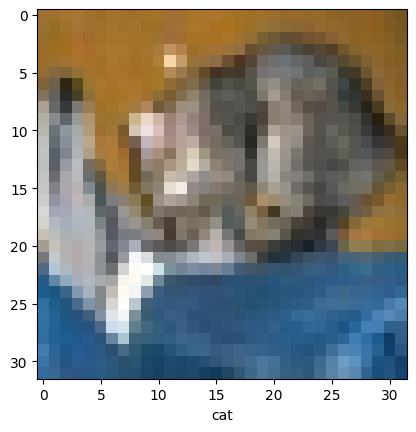

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Predicted class: cat


In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Note: Please make sure to run the first cell (-_4vL-TMUBqO) before executing this cell!
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
plt.imshow(x_test[0])
plt.xlabel(class_names[y_test[0][0]])
plt.show()

new_image = np.expand_dims(x_test[0], axis=0)

prediction = model.predict(new_image)
predicted_class = np.argmax(prediction)
print("Predicted class:", class_names[predicted_class])

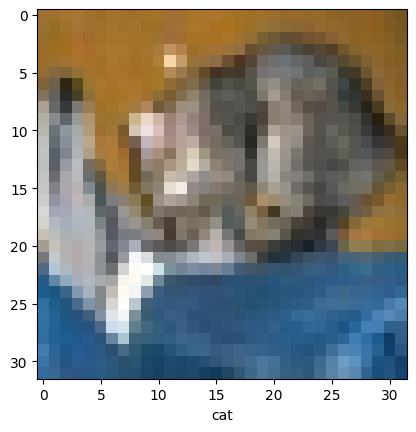

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Predicted class: cat


In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Make sure to run the first cell (-_4vL-TMUBqO) before executing this cell!
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
plt.imshow(x_test[0])
plt.xlabel(class_names[y_test[0][0]])
plt.show()

new_image = np.expand_dims(x_test[0], axis=0)

prediction = model.predict(new_image)
predicted_class = np.argmax(prediction)
print("Predicted class:", class_names[predicted_class])